# 归一化：BatchNorm → LayerNorm → RMSNorm

## 一、归一化到底在做什么？

参数初始化只在训练开始前设置权重，但随着网络加深和参数更新，中间特征的数值尺度仍可能发生变化，影响训练稳定性。因此，需要在网络计算过程中对特征进行归一化。

以 BatchNorm 和 LayerNorm 为例，基本计算方式相同：

$$y=\gamma\odot\frac{x-\mu_S}{\sqrt{\sigma_S^2+\epsilon}}+\beta$$

- 减均值：调整中心位置；除标准差：调整数值尺度。
- $\gamma,\beta$：可学习的缩放、平移参数，让输出不必固定在标准化后的尺度和中心。
- $\epsilon$：防止除零。

**关键问题不是公式，而是哪些数放在一起计算均值和方差（即统计集合 $S$）。**

假设输入为 $(B,L,d_{model})=(2,2,3)$，两个句子，每个句子有两个 Token，每个 Token 有三个特征：

$$X_0=\begin{bmatrix}1&2&3\\4&5&6\end{bmatrix},\qquad X_1=\begin{bmatrix}7&8&9\\10&11&12\end{bmatrix}$$

每一行是一个 Token，每一列是一个特征维度。接下来始终使用这组数据。

## 二、BatchNorm：同一个特征维度放在一起

回顾线性层 $Y=XW$（省略偏置）。权重矩阵 $W$ 的每一列负责生成一个输出特征，同一列权重在所有样本和 Token 间共享。因此，BatchNorm 按输出特征维度分组：**同一个特征维度的值放在一起，计算一套均值和方差。**

以上面的数据为例：

| 组 | 参与统计的值 | 均值 |
|---|---|---:|
| 特征 0 | 1, 4, 7, 10 | 5.5 |
| 特征 1 | 2, 5, 8, 11 | 6.5 |
| 特征 2 | 3, 6, 9, 12 | 7.5 |

因此，对于 $(B,L,d_{model})$，沿 $B,L$ 计算统计量，保留特征维度；共 $d_{model}$ 组。

在 CV 中，同一通道由同一个卷积核生成，因此通常也是按通道分组，对 $(B,C,H,W)$ 沿 $B,H,W$ 统计。同一组权重是这种分组的直观依据，但并不保证输出服从完全相同的分布。

**训练与推理：** BatchNorm 训练时使用当前 batch 的统计量，并通过移动平均更新 running mean / variance；推理时通常使用保存的统计量，避免输出受推理 batch 组成影响。

## 三、为什么 Transformer 通常使用 LayerNorm？

BatchNorm 会让一个 Token 的归一化结果受到其他样本、其他 Token 的影响。对于语言模型，这会带来几个问题：

- **Padding：** 假设真实特征值为 $[1,3]$，均值为 2；加入两个值为 0 的 PAD 后变为 $[1,3,0,0]$，均值变成 1。真实 Token 没变，统计量却变了。
- **序列与 batch 依赖：** 句子长度、内容和 batch 组成不同，统计量可能波动；因果语言模型训练时，跨序列位置统计还可能引入未来 Token 的信息。

既然不希望一个 Token 的归一化依赖其他 Token，就改变统计范围：**将一个 Token 的所有特征放在一起，独立计算均值和方差。** 这就是 Transformer 中的 LayerNorm。

| 组 | 参与统计的值 | 均值 |
|---|---|---:|
| 句子 0，Token 0 | 1, 2, 3 | 2 |
| 句子 0，Token 1 | 4, 5, 6 | 5 |
| 句子 1，Token 0 | 7, 8, 9 | 8 |
| 句子 1，Token 1 | 10, 11, 12 | 11 |

因此，沿最后一个维度 $d_{model}$ 统计，共 $B\times L$ 组。均值和方差形状为 $(B,L,1)$；缩放和平移参数 $\gamma,\beta$ 的形状为 $(d_{model},)$，所有 Token 共享。训练与推理都使用当前 Token 的统计量，不需要 running stats。

下面用颜色直观展示：**同一种颜色的数值参与同一组统计。**

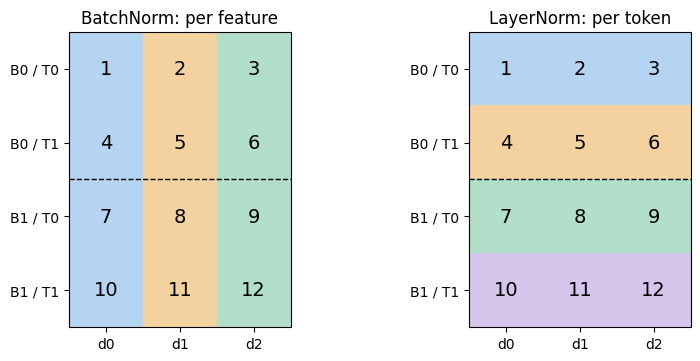

BatchNorm mean: [5.5 6.5 7.5]
LayerNorm mean:
 [[ 2.  5.]
 [ 8. 11.]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 两个句子，每个句子两个 Token，每个 Token 三个特征
X = np.arange(1, 13).reshape(2, 2, 3)
# 仅为绘图，将两个句子的 Token 排成四行；实际输入仍是三维张量
values = X.reshape(4, 3)

# BN 按列分组；LN 按行分组
bn_groups = np.tile(np.arange(3), (4, 1))
ln_groups = np.tile(np.arange(4)[:, None], (1, 3))
colors = ListedColormap(['#b5d4f1', '#f4d2a0', '#b1dfca', '#d6c6ec'])
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')
for ax, groups, title in zip(axes, [bn_groups, ln_groups],
                             ['BatchNorm: per feature', 'LayerNorm: per token']):
    ax.imshow(groups, cmap=colors, vmin=0, vmax=3)
    for i in range(4):
        for j in range(3):
            ax.text(j, i, values[i, j], ha='center', va='center', fontsize=14)
    ax.set_xticks(range(3), ['d0', 'd1', 'd2'])
    ax.set_yticks(range(4), ['B0 / T0', 'B0 / T1', 'B1 / T0', 'B1 / T1'])
    ax.axhline(1.5, color='black', linestyle='--', linewidth=1)
    ax.set_title(title, fontsize=12)
plt.show()

# 观察两种统计量：BN 每列一个均值，LN 每行一个均值
print('BatchNorm mean:', X.mean(axis=(0, 1)))
print('LayerNorm mean:\n', X.mean(axis=-1))

## 四、从 LayerNorm 推导 RMSNorm

### 1. 展开 LayerNorm 的公式

暂时忽略可学习参数 $\gamma,\beta$，将方差的计算公式代入 LayerNorm：

$$\hat{x}_i=\frac{x_i-\mu}{\sqrt{\frac{1}{d}\sum_{j=1}^{d}(x_j-\mu)^2+\epsilon}}$$

均值 $\mu$ 出现在两个地方：分子减均值，负责中心化；分母中的平方差，负责衡量**中心化后的特征**的数值尺度。因此，LayerNorm 是先中心化，再对中心化后的向量进行缩放。

### 2. 省略中心化，为什么分母也要改变？

Zhang 和 Sennrich（2019）在 [Root Mean Square Layer Normalization](https://arxiv.org/abs/1910.07467) 中，通过多个任务的实验发现，移除中心化操作、仅保留尺度归一化，仍能取得与 LayerNorm 相当的性能，同时降低计算开销。因此，可以在 LayerNorm 的基础上省略与均值相关的计算。

既然不再进行中心化，分子就直接使用原始特征 $x_i$；分母也应衡量原始向量的数值尺度，而不是中心化后的向量，即将平方差 $(x_j-\mu)^2$ 替换为 $x_j^2$。

$$\underbrace{\frac{x_i-\mu}{\sqrt{\frac{1}{d}\sum_{j=1}^{d}(x_j-\mu)^2+\epsilon}}}_{\text{LayerNorm（标准化部分）}}\quad\longrightarrow\quad\underbrace{\frac{x_i}{\sqrt{\frac{1}{d}\sum_{j=1}^{d}x_j^2+\epsilon}}}_{\text{RMSNorm（归一化部分）}}$$

此时分母（不计 $\epsilon$）恰好是均方根（Root Mean Square）：

$$\operatorname{RMS}(x)=\sqrt{\frac{1}{d}\sum_{j=1}^{d}x_j^2}$$

例如 $x=[10,10,10]$ 的标准差为 0，但 RMS 为 10。标准差衡量围绕均值的波动，RMS 衡量相对于 0 的整体数值大小。两者满足 $\operatorname{RMS}^2=\sigma^2+\mu^2$，因此只有当均值为 0 时，两者才相等。

### 3. 为什么除以 RMS 就能控制尺度？

忽略 $\epsilon$，对于非零向量，令 $\hat{x}_i=x_i/\operatorname{RMS}(x)$，则：

$$\operatorname{RMS}(\hat{x})^2=\frac{\frac1d\sum_i x_i^2}{\operatorname{RMS}(x)^2}=1$$

所以除以 RMS 后，向量的均方根变为 1，同时保留原始向量各分量的比例。最后加入可学习的缩放参数 $\gamma$，得到标准 RMSNorm（不使用偏移参数 $\beta$）：

$$\boxed{y_i=\gamma_i\frac{x_i}{\sqrt{\frac1d\sum_{j=1}^d x_j^2+\epsilon}}}$$

与 LayerNorm 一样，RMSNorm 对每个 Token 独立计算统计量。**两者的区别是先中心化再缩放，还是直接缩放。** 省略中心化的有效性具有实验依据，并不意味着所有网络都不需要中心化，也不要求原始特征的均值必须为 0。

下面观察同一个向量放大 10 倍或整体加 10 之后的归一化结果（为便于比较，取 $\gamma=1,\beta=0$，忽略 $\epsilon$）。

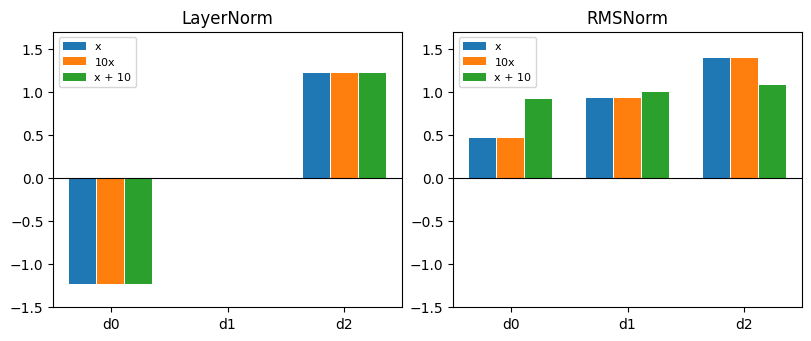

LayerNorm results:
 [[-1.225  0.     1.225]
 [-1.225  0.     1.225]
 [-1.225  0.     1.225]]
RMSNorm results:
 [[0.463 0.926 1.389]
 [0.463 0.926 1.389]
 [0.915 0.998 1.081]]


In [2]:
x = np.array([1., 2., 3.])
inputs = [x, x * 10, x + 10]
labels = ['x', '10x', 'x + 10']

# LN：先减去均值，再除以标准差
ln = [(v - v.mean()) / v.std() for v in inputs]
# RMSNorm：直接除以均方根，不减均值
rms = [v / np.sqrt(np.mean(v ** 2)) for v in inputs]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), layout='constrained')
for ax, results, title in zip(axes, [ln, rms], ['LayerNorm', 'RMSNorm']):
    for i, (v, label) in enumerate(zip(results, labels)):
        ax.bar(np.arange(3) + (i - 1) * 0.24, v, width=0.23, label=label)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(range(3), ['d0', 'd1', 'd2'])
    ax.set_ylim(-1.5, 1.7)
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.show()

# 两者都消除了正向整体缩放；只有 LN 消除了整体平移（忽略 eps）
print('LayerNorm results:\n', np.round(ln, 3))
print('RMSNorm results:\n', np.round(rms, 3))

## 五、总结

| 方法 | 哪些维度参与统计（B,L,D） | 核心操作 |
|---|---|---|
| BatchNorm | B、L（每个特征一组） | 减均值、除标准差、仿射变换 |
| LayerNorm | D（每个 Token 一组） | 减均值、除标准差、仿射变换 |
| RMSNorm | D（每个 Token 一组） | 除均方根、可学习缩放 |

**BatchNorm 到 LayerNorm 改变的是统计范围；LayerNorm 到 RMSNorm 改变的是归一化操作。** 三者均用于调整特征数值条件，而不是像 FFN 那样学习新的特征组合。

参考：原始学习材料《粘贴的文本 (1).txt》；其中列出的 RMSNorm 相关论文：[Root Mean Square Layer Normalization](https://arxiv.org/abs/1910.07467)、[HybridNorm](https://proceedings.neurips.cc/paper_files/paper/2025/file/23a1e7765b22c7e2ffdabf2e6b5dbc44-Paper-Conference.pdf)、[Geometric Interpretation of Layer Normalization and a Comparative Analysis with RMSNorm](https://aclanthology.org/2026.findings-eacl.20/)。此处仅整理材料中的设计思路，不独立核查论文具体实验数字。